# Evaluación del impacto y mejora de la focalización del programa HSNP en Kenia



## Preparación del entorno y carga de datos


In [ ]:
from pathlib import Path
import re
import warnings

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 120)
RANDOM_STATE = 42


In [ ]:
# En Colab, montar Google Drive. En local se utiliza la carpeta del notebook.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/TFM data')
except ImportError:
    ROOT = Path.cwd()

print('Carpeta de trabajo:', ROOT)


Mounted at /content/drive
Carpeta de trabajo: /content/drive/MyDrive/TFM data


In [ ]:
ROUND_PATHS = {
    'baseline': ROOT / 'KEN_2009_HSNP-BL_v01_M_ASCII_SPSS_SAS' / 'KEN_2009_HSNP-BL_v01_M_ASCII_SPSS_SAS',
    'followup1': ROOT / 'KEN_2010_HSNP-FU1_v01_M_ASCII_SPSS_SAS' / 'KEN_2010_HSNP-FU1_v01_M_ASCII_SPSS_SAS',
    'followup2': ROOT / 'KEN_2012_HSNP-FU2_v01_M_ASCII_SPSS_SAS' / 'KEN_2012_HSNP-FU2_v01_M_ASCII_SPSS_SAS'
}

for ronda, ruta in ROUND_PATHS.items():
    print(ronda, '->', ruta.exists())

baseline -> True
followup1 -> True
followup2 -> True


In [ ]:
def read_sps_fixed_width(folder, table_name):
    """Lee un archivo ASCII usando las posiciones indicadas en su sintaxis SPSS."""
    syntax_path = folder / 'SPSS_Syntax' / f'{table_name}.sps'
    data_path = folder / 'ASCII' / f'{table_name}.dat'
    syntax = syntax_path.read_text(encoding='latin-1')

    block = re.search(
        r'DATA LIST.*?FIXED\s*/(.*?)\.\s*VAR LABELS',
        syntax,
        re.S | re.I
    ).group(1)

    fields = re.findall(
        r'\b([A-Za-z_][A-Za-z0-9_]*)\s+(\d+)(?:-(\d+))?(?:\s+\(A\))?',
        block
    )

    names = [name for name, _, _ in fields]
    colspecs = [(int(start) - 1, int(end or start)) for _, start, end in fields]

    return pd.read_fwf(
        data_path,
        colspecs=colspecs,
        names=names,
        dtype=str,
        encoding='latin-1'
    )


def clean_id(series):
    return series.astype('string').str.strip()


def to_numeric(series):
    return pd.to_numeric(series.astype('string').str.strip(), errors='coerce')


### Variables demográficas del hogar


In [ ]:
def household_demographics(member):
    member = member.copy()
    member['HHID'] = clean_id(member['HHID'])
    member['age'] = to_numeric(member['T2_Q04'])
    member['sex'] = to_numeric(member['T2_Q03'])

    # En baseline y follow-up 1, T2_Q06 identifica la relación con el proveedor principal
    # En follow-up 2 esa información se encuentra en T2_Q05.
    relationship_col = 'T2_Q06' if 'T2_Q06' in member.columns else 'T2_Q05'
    member['relationship'] = to_numeric(member[relationship_col])

    member['is_child'] = member['age'] < 18
    member['is_elderly'] = member['age'] >= 60
    member['is_female'] = member['sex'] == 2

    household = member.groupby('HHID').agg(
        household_size=('HHID', 'size'),
        children=('is_child', 'sum'),
        elderly=('is_elderly', 'sum'),
        female_share=('is_female', 'mean'),
        mean_age=('age', 'mean')
    )

    head = (
        member.loc[member['relationship'] == 1, ['HHID', 'age', 'sex']]
        .drop_duplicates('HHID')
        .rename(columns={'age': 'head_age', 'sex': 'head_sex'})
        .set_index('HHID')
    )

    return household.join(head, how='left').reset_index()


### Construcción de cada ronda


- `disaggregation_data`: consumo, gasto, quintil y pesos muestrales;
- `HHData`: seguridad alimentaria, condiciones de vida, ahorro y crédito;
- `HHMember`: composición demográfica del hogar.

La variable `food_insecurity` toma valor 1 cuando el hogar declara haber pasado días enteros sin comer durante el peor periodo y 0 cuando responde que no.


In [ ]:
def load_round(round_name):
    folder = ROUND_PATHS[round_name]

    disagg = read_sps_fixed_width(folder, 'disaggregation_data')
    disagg.columns = ['HHID' if c.lower() == 'hhid' else c for c in disagg.columns]
    disagg['HHID'] = clean_id(disagg['HHID'])

    hh = read_sps_fixed_width(folder, 'HHData')
    hh['HHID'] = clean_id(hh['HHID'])

    member = read_sps_fixed_width(folder, 'HHMember')
    demo = household_demographics(member)

    hh_variables = [
        'HHID', 'CLID', 'T7GQ03a', 'T7GQ03b', 'T7GQ06a', 'T7GQ06b',
        'T7GQ08', 'T7HQ01', 'T7HQ02', 'T7JQ04', 'T7JQ09',
        'T7KQ01', 'T7KQ04', 'T7KQ11'
    ]
    hh_variables = [c for c in hh_variables if c in hh.columns]

    data = (
        disagg
        .merge(hh[hh_variables], on='HHID', how='left')
        .merge(demo, on='HHID', how='left')
    )

    if round_name == 'baseline':
        link = read_sps_fixed_width(folder, 'comq_linking_BL')
        link['HHID'] = clean_id(link['HHID'])
        data = data.merge(
            link[['HHID', 'treatmentlocation']].drop_duplicates('HHID'),
            on='HHID',
            how='left'
        )

        cluster = read_sps_fixed_width(folder, 'ClusterMaster')
        cluster.columns = ['CLID' if c.lower() == 'clid' else c for c in cluster.columns]
        cluster['CLID'] = clean_id(cluster['CLID'])
        data['CLID'] = clean_id(data['CLID'])
        data = data.merge(
            cluster[['CLID', 'TargetingCode', 'TargetingMechanism']].drop_duplicates('CLID'),
            on='CLID',
            how='left'
        )

    numeric_cols = [
        'hh_wt', 'treatmentlocation', 'BenStatus', 'TargetingCode', 'HHSize',
        'HHNumAdeq', 'totexp', 'rtotexp', 'pcexp', 'rpcexp', 'radeqexp',
        'ExpEducPChild1Month', 'ExpFoodPAdeq1Month', 'ExpHealthPCap1Month',
        'ExpShareFood', 'ExpTotalPAdeq1Month', 'eduexp', 'foodexp', 'healthexp',
        'nfoodexp', 'pcfoodexp', 'quintile', 'T7GQ03a', 'T7GQ03b', 'T7GQ06a',
        'T7GQ06b', 'T7GQ08', 'T7HQ01', 'T7HQ02', 'T7JQ04', 'T7JQ09',
        'T7KQ01', 'T7KQ04', 'T7KQ11', 'household_size', 'children', 'elderly',
        'female_share', 'mean_age', 'head_age', 'head_sex'
    ]

    for col in numeric_cols:
        if col in data.columns:
            data[col] = to_numeric(data[col])

    data['food_insecurity'] = np.nan
    data.loc[data['T7GQ08'] == 1, 'food_insecurity'] = 1
    data.loc[data['T7GQ08'] == 2, 'food_insecurity'] = 0
    data['round'] = round_name
    return data


In [ ]:
baseline = load_round('baseline')
followup1 = load_round('followup1')
followup2 = load_round('followup2')

panel_long = pd.concat([baseline, followup1, followup2], ignore_index=True, sort=False)

print('Baseline:', baseline.shape)
print('Primer seguimiento:', followup1.shape)
print('Segundo seguimiento:', followup2.shape)
print('Panel apilado:', panel_long.shape)


Baseline: (5109, 48)
Primer seguimiento: (4637, 48)
Segundo seguimiento: (2436, 46)
Panel apilado: (12182, 50)


In [ ]:
import os

# Listar el contenido del directorio ROOT para verificar la estructura de carpetas
print(f"Contenido de {ROOT}:")
for item in os.listdir(ROOT):
    print(f"- {item}")

Contenido de /content/drive/MyDrive/TFM data:
- NuestrasFunciones.py
- KEN_2009_HSNP-BL_v01_M_ASCII_SPSS_SAS
- KEN_2010_HSNP-FU1_v01_M_ASCII_SPSS_SAS
- KEN_2012_HSNP-FU2_v01_M_ASCII_SPSS_SAS
- tfm_hsnp_model


In [ ]:
import os

# Listar el contenido de la carpeta 'baseline' para verificar las subcarpetas 'SPSS_Syntax' y 'ASCII'
print(f"\nContenido de {ROUND_PATHS['baseline']}:")
for item in os.listdir(ROUND_PATHS['baseline']):
    print(f"- {item}")



Contenido de /content/drive/MyDrive/TFM data/KEN_2009_HSNP-BL_v01_M_ASCII_SPSS_SAS/KEN_2009_HSNP-BL_v01_M_ASCII_SPSS_SAS:
- SAS_Syntax
- ASCII
- SPSS_Syntax


In [ ]:
ids_baseline = set(baseline['HHID'])
ids_fu1 = set(followup1['HHID'])
ids_fu2 = set(followup2['HHID'])

print('Hogares baseline y FU1:', len(ids_baseline & ids_fu1))
print('Hogares baseline y FU2:', len(ids_baseline & ids_fu2))
print('Hogares en las tres rondas:', len(ids_baseline & ids_fu1 & ids_fu2))


Hogares baseline y FU1: 4637
Hogares baseline y FU2: 2436
Hogares en las tres rondas: 2292


## Análisis exploratorio y calidad de los datos


In [ ]:
def data_summary(df):
    return pd.DataFrame({
        'tipo': df.dtypes.astype(str),
        'n_missing': df.isna().sum(),
        'pct_missing': (df.isna().mean() * 100).round(2),
        'n_unicos': df.nunique(dropna=True)
    }).sort_values('pct_missing', ascending=False)

display(data_summary(panel_long).head(30))


,tipo,n_missing,pct_missing,n_unicos
adeqexp,object,7076,58.09,2569
adeqfoodexp,object,7076,58.09,2122
HHSize,Int64,5109,41.94,18
BenStatus,Int64,5109,41.94,2
T7JQ09,Float64,5109,41.94,2
ExpEducPChild1Month,Int64,2492,20.46,753
T7HQ01,Int64,2439,20.02,4
T7HQ02,Int64,2439,20.02,6
head_age,Int64,514,4.22,86
head_sex,Int64,513,4.21,2


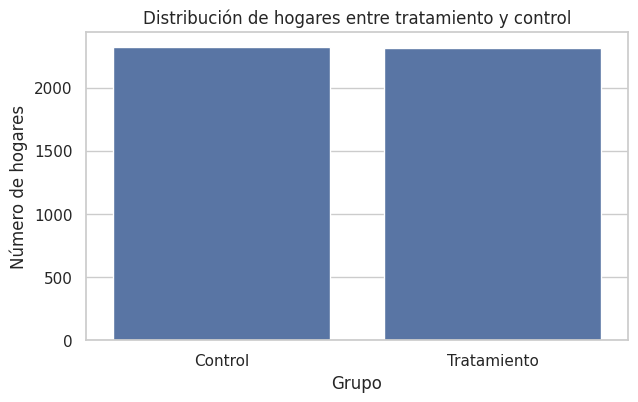

treatmentlocation
0    2322
1    2315
Name: count, dtype: Int64


In [ ]:
# Distribución del tratamiento en el primer seguimiento
tratamiento = followup1['treatmentlocation'].map({0: 'Control', 1: 'Tratamiento'})

plt.figure(figsize=(7, 4))
sns.countplot(x=tratamiento, order=['Control', 'Tratamiento'])
plt.title('Distribución de hogares entre tratamiento y control')
plt.xlabel('Grupo')
plt.ylabel('Número de hogares')
plt.show()

print(followup1['treatmentlocation'].value_counts().sort_index())


In [ ]:
# Evolución descriptiva de los principales resultados
outcomes = ['food_insecurity', 'radeqexp', 'ExpShareFood']
display(panel_long.groupby(['round', 'treatmentlocation'])[outcomes].mean().round(3))


food_insecurity  radeqexp  ExpShareFood
round     treatmentlocation                                         
baseline  0                            0.641  1998.016        77.541
          1                            0.605  2018.017        76.318
followup1 0                            0.590  1790.199        80.675
          1                            0.525  1885.326         79.14
followup2 0                            0.359  1624.033        82.009
          1                            0.384   1865.97        79.016

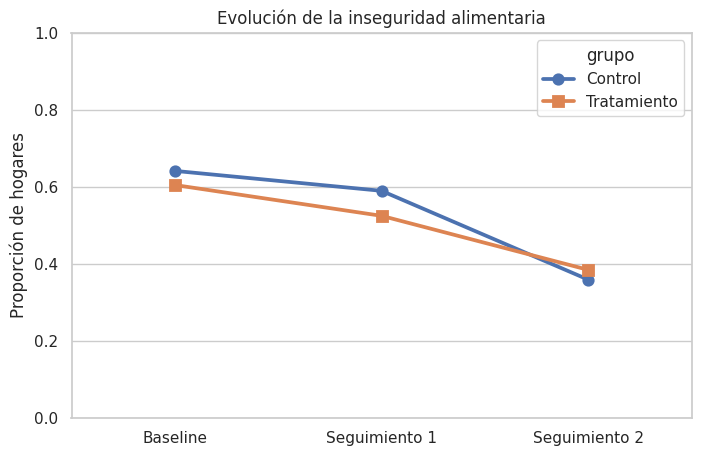

In [ ]:
plot_data = (
    panel_long.groupby(['round', 'treatmentlocation'], as_index=False)['food_insecurity']
    .mean()
)
plot_data['grupo'] = plot_data['treatmentlocation'].map({0: 'Control', 1: 'Tratamiento'})
plot_data['ronda'] = plot_data['round'].map({
    'baseline': 'Baseline', 'followup1': 'Seguimiento 1', 'followup2': 'Seguimiento 2'
})

plt.figure(figsize=(8, 5))
sns.pointplot(data=plot_data, x='ronda', y='food_insecurity', hue='grupo', markers=['o', 's'])
plt.title('Evolución de la inseguridad alimentaria')
plt.xlabel('')
plt.ylabel('Proporción de hogares')
plt.ylim(0, 1)
plt.show()


### Comparabilidad inicial


In [ ]:
balance_vars = [
    'radeqexp', 'ExpShareFood', 'household_size', 'children',
    'elderly', 'head_age', 'female_share', 'food_insecurity'
]

balance = baseline.groupby('treatmentlocation')[balance_vars].mean().T
balance.columns = ['Control', 'Tratamiento']
balance['Diferencia'] = balance['Tratamiento'] - balance['Control']
display(balance.round(3))


,Control,Tratamiento,Diferencia
radeqexp,1998.015501,2018.016627,20.001126
ExpShareFood,77.540938,76.31829,-1.222648
household_size,5.362083,5.623813,0.261731
children,2.921304,3.106013,0.184709
elderly,0.446343,0.40269,-0.043654
head_age,44.912922,44.368817,-0.544106
female_share,0.496101,0.487428,-0.008673
food_insecurity,0.641352,0.60467,-0.036682


## Evaluación del impacto

El coeficiente de la interacción `treatment × post` representa el cambio adicional observado en el grupo de tratamiento respecto al cambio del grupo de control. Para facilitar la interpretación se analiza: inseguridad alimentaria severa,consumo real mensual por adulto equivalente, proporción del gasto destinada a alimentos.

En el modelo binario de inseguridad alimentaria se utiliza una especificación lineal para que el efecto se interprete en puntos porcentuales.


In [ ]:
import statsmodels.formula.api as smf


def make_did_data(base, followup, outcome):
    ids = set(base['HHID']) & set(followup['HHID'])
    pre = base.loc[base['HHID'].isin(ids), ['HHID', 'CLID', 'treatmentlocation', outcome]].copy()
    post = followup.loc[followup['HHID'].isin(ids), ['HHID', 'CLID', 'treatmentlocation', outcome]].copy()
    pre['post'] = 0
    post['post'] = 1
    return pd.concat([pre, post], ignore_index=True).dropna(subset=[outcome, 'treatmentlocation'])


def estimate_did(base, followup, outcome):
    did_data = make_did_data(base, followup, outcome)
    model = smf.ols(
        f'{outcome} ~ treatmentlocation + post + treatmentlocation:post',
        data=did_data
    ).fit(cov_type='cluster', cov_kwds={'groups': did_data['CLID']})
    return model, did_data


In [ ]:
did_results = []

for followup_name, followup_df in [('Seguimiento 1', followup1), ('Seguimiento 2', followup2)]:
    for outcome in ['food_insecurity', 'radeqexp', 'ExpShareFood']:
        model, did_data = estimate_did(baseline, followup_df, outcome)
        effect = model.params['treatmentlocation:post']
        pvalue = model.pvalues['treatmentlocation:post']
        did_results.append({
            'seguimiento': followup_name,
            'resultado': outcome,
            'efecto_did': effect,
            'p_valor': pvalue,
            'n_observaciones': int(model.nobs)
        })

did_results = pd.DataFrame(did_results)
display(did_results.round(4))


,seguimiento,resultado,efecto_did,p_valor,n_observaciones
0,Seguimiento 1,food_insecurity,-0.0282,0.6984,9214
1,Seguimiento 1,radeqexp,64.3382,0.5351,9214
2,Seguimiento 1,ExpShareFood,-0.3455,0.8196,9214
3,Seguimiento 2,food_insecurity,0.0480,0.6330,4857
4,Seguimiento 2,radeqexp,173.7792,0.1738,4857
5,Seguimiento 2,ExpShareFood,-1.9817,0.2983,4857


In [ ]:
# Resumen detallado del modelo principal: inseguridad alimentaria a corto plazo
did_food_fu1, did_food_data = estimate_did(baseline, followup1, 'food_insecurity')
print(did_food_fu1.summary())


                            OLS Regression Results                            
Dep. Variable:        food_insecurity   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     1.333
Date:                Mon, 31 Aug 2026   Prob (F-statistic):              0.275
Time:                        10:37:11   Log-Likelihood:                -6501.6
No. Observations:                9214   AIC:                         1.301e+04
Df Residuals:                    9210   BIC:                         1.304e+04
Df Model:                           3                                         
Covariance Type:              cluster                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  0

## Modelización predictiva de la vulnerabilidad posterior

Identificar, utilizando únicamente información inicial, qué hogares tienen mayor probabilidad de continuar sufriendo inseguridad alimentaria en el primer seguimiento.

La variable objetivo es `food_insecurity` en el seguimiento 1. Se emplean variables de baseline para evitar fuga de información.


In [ ]:
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)


In [ ]:
baseline_features = [
    'treatmentlocation', 'TargetingCode', 'TargetingMechanism',
    'radeqexp', 'ExpShareFood', 'ExpFoodPAdeq1Month',
    'ExpHealthPCap1Month', 'ExpEducPChild1Month',
    'household_size', 'children', 'elderly', 'female_share',
    'mean_age', 'head_age', 'head_sex', 'quintile',
    'T7GQ03a', 'T7GQ03b', 'T7GQ06a', 'T7GQ06b',
    'T7HQ01', 'T7KQ01', 'T7KQ04', 'T7KQ11'
]

target_fu1 = followup1[['HHID', 'food_insecurity']].rename(
    columns={'food_insecurity': 'food_insecurity_fu1'}
)

model_data = (
    baseline[['HHID'] + baseline_features]
    .merge(target_fu1, on='HHID', how='inner')
    .dropna(subset=['food_insecurity_fu1'])
)

X = model_data[baseline_features]
y = model_data['food_insecurity_fu1'].astype(int)

# Normalizar tipos y valores ausentes para scikit-learn.
X = X.copy()
for col in X.columns:
    if col == 'TargetingMechanism':
        X[col] = X[col].astype(object).where(X[col].notna(), np.nan)
    else:
        X[col] = pd.to_numeric(X[col], errors='coerce').astype(float)

print('Muestra de modelización:', model_data.shape)
print(y.value_counts())
print(y.value_counts(normalize=True).round(3))


Muestra de modelización: (4636, 26)
food_insecurity_fu1
1    2583
0    2053
Name: count, dtype: int64
food_insecurity_fu1
1    0.557
0    0.443
Name: proportion, dtype: float64


In [ ]:
categorical_cols = ['TargetingMechanism', 'TargetingCode', 'head_sex', 'quintile']
numeric_cols = [c for c in baseline_features if c not in categorical_cols]

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_cols),
    ('cat', categorical_pipeline, categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print('Entrenamiento:', X_train.shape)
print('Test:', X_test.shape)


Entrenamiento: (3477, 24)
Test: (1159, 24)


In [ ]:
models = {
    'Regresión logística': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Árbol de decisión': DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=20, class_weight='balanced', random_state=RANDOM_STATE
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=300, min_samples_leaf=10, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=1
    ),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, estimator in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', estimator)
    ])
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={'auc': 'roc_auc', 'recall': 'recall', 'f1': 'f1'}
    )
    cv_rows.append({
        'modelo': name,
        'auc_cv': scores['test_auc'].mean(),
        'recall_cv': scores['test_recall'].mean(),
        'f1_cv': scores['test_f1'].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values('auc_cv', ascending=False)
print('Resultados medios de validación cruzada:')
display(cv_results.round(3))

fitted_models = {}
metrics_rows = []

for name, estimator in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', estimator)
    ])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    proba = pipeline.predict_proba(X_test)[:, 1]

    metrics_rows.append({
        'modelo': name,
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0),
        'f1': f1_score(y_test, pred, zero_division=0),
        'auc': roc_auc_score(y_test, proba)
    })
    fitted_models[name] = pipeline

model_results = pd.DataFrame(metrics_rows).sort_values('auc', ascending=False)
display(model_results.round(3))


Resultados medios de validación cruzada:


,modelo,auc_cv,recall_cv,f1_cv
2,Random Forest,0.762,0.730,0.736
3,Gradient Boosting,0.761,0.768,0.745
0,Regresión logística,0.737,0.703,0.714
1,Árbol de decisión,0.724,0.685,0.710


,modelo,accuracy,precision,recall,f1,auc
2,Random Forest,0.723,0.765,0.726,0.745,0.787
3,Gradient Boosting,0.721,0.735,0.782,0.758,0.781
1,Árbol de decisión,0.706,0.742,0.723,0.733,0.759
0,Regresión logística,0.701,0.742,0.711,0.726,0.757


In [ ]:
# Optimización del Random Forest con GridSearchCV

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

param_grid = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [None, 5, 10, 15],
    'model__min_samples_leaf': [5, 10, 20],
    'model__max_features': ['sqrt', 'log2']
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print('Mejores parámetros:')
print(grid_search.best_params_)
print('Mejor AUC medio en CV:', round(grid_search.best_score_, 3))

rf_grid = grid_search.best_estimator_

rf_grid_pred = rf_grid.predict(X_test)
rf_grid_proba = rf_grid.predict_proba(X_test)[:, 1]

grid_metrics = {
    'modelo': 'Random Forest optimizado',
    'accuracy': accuracy_score(y_test, rf_grid_pred),
    'precision': precision_score(y_test, rf_grid_pred, zero_division=0),
    'recall': recall_score(y_test, rf_grid_pred, zero_division=0),
    'f1': f1_score(y_test, rf_grid_pred, zero_division=0),
    'auc': roc_auc_score(y_test, rf_grid_proba)
}

model_results = pd.concat(
    [model_results, pd.DataFrame([grid_metrics])],
    ignore_index=True
).sort_values('auc', ascending=False)

fitted_models['Random Forest optimizado'] = rf_grid

display(model_results.round(3))

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Mejores parámetros:
{'model__max_depth': 15, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__n_estimators': 300}
Mejor AUC medio en CV: 0.767


,modelo,accuracy,precision,recall,f1,auc
4,Random Forest optimizado,0.726,0.759,0.743,0.751,0.791
0,Random Forest,0.723,0.765,0.726,0.745,0.787
1,Gradient Boosting,0.721,0.735,0.782,0.758,0.781
2,Árbol de decisión,0.706,0.742,0.723,0.733,0.759
3,Regresión logística,0.701,0.742,0.711,0.726,0.757


Mejor modelo según AUC: Random Forest optimizado
              precision    recall  f1-score   support

           0       0.69      0.70      0.69       513
           1       0.76      0.74      0.75       646

    accuracy                           0.73      1159
   macro avg       0.72      0.72      0.72      1159
weighted avg       0.73      0.73      0.73      1159



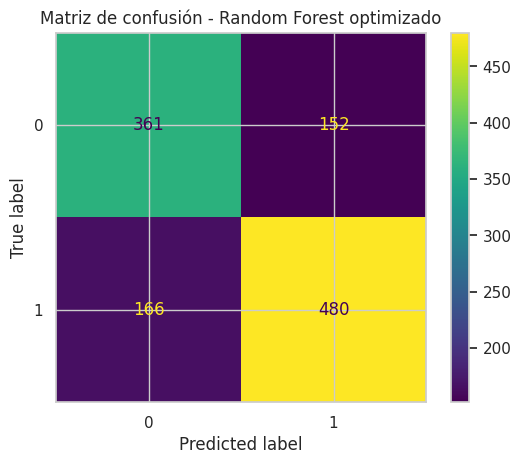

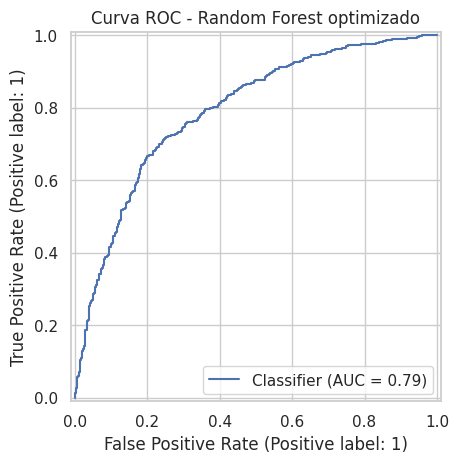

In [ ]:
# El modelo final se selecciona por su rendimiento en validación cruzada
best_model_name = 'Random Forest optimizado'
best_model = fitted_models[best_model_name]
best_pred = best_model.predict(X_test)
best_proba = best_model.predict_proba(X_test)[:, 1]

print('Mejor modelo según AUC:', best_model_name)
print(classification_report(y_test, best_pred))

ConfusionMatrixDisplay.from_predictions(y_test, best_pred)
plt.title(f'Matriz de confusión - {best_model_name}')
plt.show()

RocCurveDisplay.from_predictions(y_test, best_proba)
plt.title(f'Curva ROC - {best_model_name}')
plt.show()


## Interpretabilidad

Se utiliza la importancia de variables del Random Forest y los coeficientes de la regresión logística.


,variable,importancia
1,num__radeqexp,0.096725
2,num__ExpShareFood,0.092847
13,num__T7GQ03b,0.083469
3,num__ExpFoodPAdeq1Month,0.078677
16,num__T7HQ01,0.072562
10,num__mean_age,0.068335
11,num__head_age,0.058626
15,num__T7GQ06b,0.048169
9,num__female_share,0.042686
4,num__ExpHealthPCap1Month,0.041802


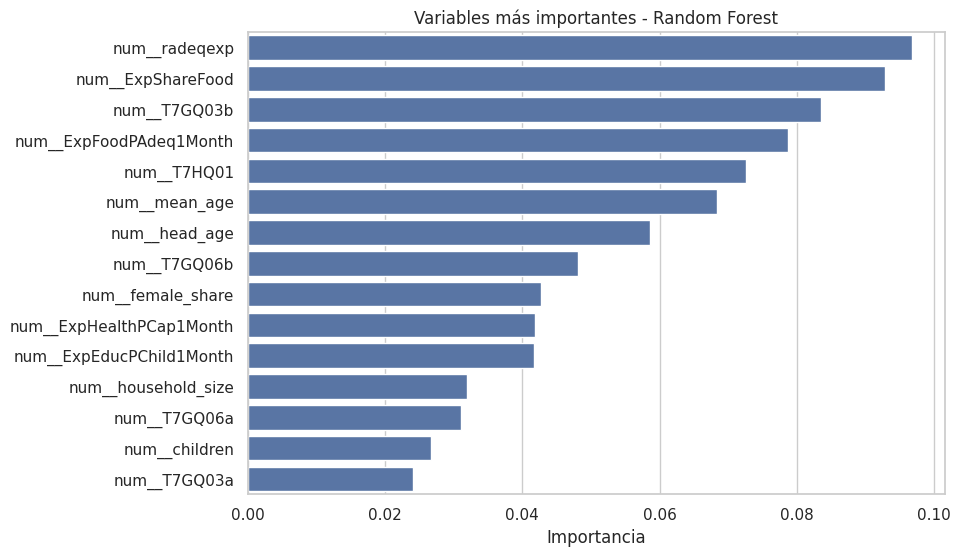

In [ ]:
def feature_names_from_pipeline(pipeline):
    prep = pipeline.named_steps['preprocessor']
    return prep.get_feature_names_out()


rf_pipeline = best_model
rf_names = feature_names_from_pipeline(rf_pipeline)
rf_importance = pd.DataFrame({
    'variable': rf_names,
    'importancia': rf_pipeline.named_steps['model'].feature_importances_
}).sort_values('importancia', ascending=False)

display(rf_importance.head(20))

plt.figure(figsize=(9, 6))
sns.barplot(data=rf_importance.head(15), x='importancia', y='variable')
plt.title('Variables más importantes - Random Forest')
plt.xlabel('Importancia')
plt.ylabel('')
plt.show()


In [ ]:
logit_pipeline = fitted_models['Regresión logística']
logit_names = feature_names_from_pipeline(logit_pipeline)
logit_coef = pd.DataFrame({
    'variable': logit_names,
    'coeficiente': logit_pipeline.named_steps['model'].coef_[0]
})
logit_coef['coef_abs'] = logit_coef['coeficiente'].abs()
logit_coef = logit_coef.sort_values('coef_abs', ascending=False)

display(logit_coef.head(20))


,variable,coeficiente,coef_abs
1,num__radeqexp,-0.799145,0.799145
3,num__ExpFoodPAdeq1Month,0.649463,0.649463
28,cat__quintile_1.0,0.385418,0.385418
13,num__T7GQ03b,0.364703,0.364703
16,num__T7HQ01,0.281673,0.281673
15,num__T7GQ06b,0.201945,0.201945
19,num__T7KQ11,-0.195916,0.195916
2,num__ExpShareFood,0.167598,0.167598
14,num__T7GQ06a,0.164077,0.164077
29,cat__quintile_2.0,-0.159009,0.159009


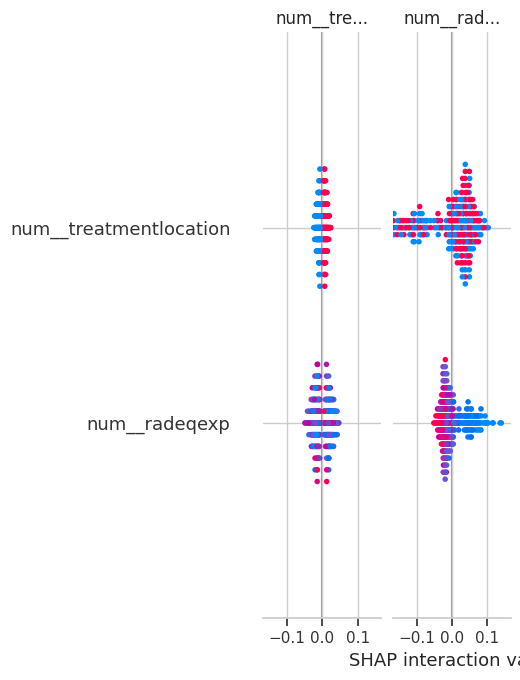

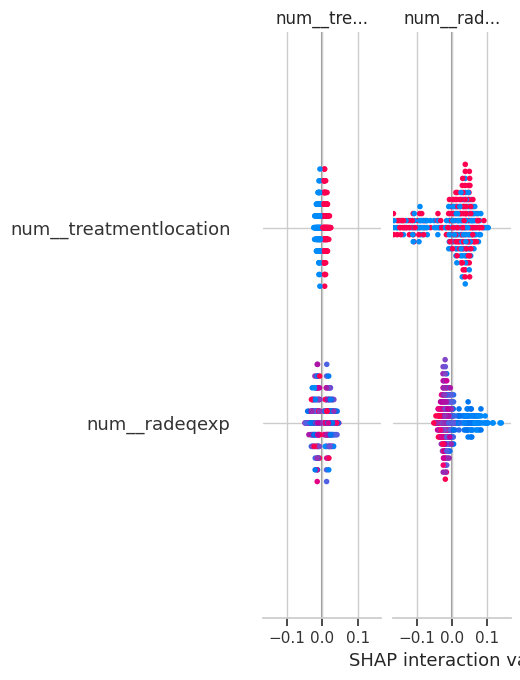

In [ ]:
import shap
# Interpretabilidad con SHAP para el mejor modelo de árboles

tree_model_names = ['Random Forest', 'Random Forest optimizado', 'Gradient Boosting']

if best_model_name in tree_model_names:
    shap_model = best_model
else:
    shap_model = fitted_models.get('Random Forest optimizado', fitted_models['Random Forest'])

X_test_transformed = shap_model.named_steps['preprocessor'].transform(X_test)
feature_names = shap_model.named_steps['preprocessor'].get_feature_names_out()

if hasattr(X_test_transformed, 'toarray'):
    X_test_transformed = X_test_transformed.toarray()

X_test_shap = pd.DataFrame(X_test_transformed, columns=feature_names)

# Para que no tarde demasiado
X_shap_sample = X_test_shap.sample(
    n=min(300, len(X_test_shap)),
    random_state=RANDOM_STATE
)

explainer = shap.TreeExplainer(shap_model.named_steps['model'])
shap_values = explainer.shap_values(X_shap_sample)

# En clasificación binaria, algunas versiones devuelven una lista [clase 0, clase 1]
if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]
else:
    shap_values_to_plot = shap_values

shap.summary_plot(shap_values_to_plot, X_shap_sample, plot_type='bar')

# Gráfico más completo
shap.summary_plot(shap_values_to_plot, X_shap_sample)

In [ ]:
# Simulación simple de focalización basada en el modelo

targeting = X_test.copy()
targeting['vulnerable_real'] = y_test.values
targeting['probabilidad_vulnerabilidad'] = best_model.predict_proba(X_test[baseline_features])[:, 1]

# Supuesto: el programa solo puede atender al 20% de hogares con mayor riesgo
coverage_rate = 0.20
n_selected = int(len(targeting) * coverage_rate)

targeting_model = targeting.sort_values(
    'probabilidad_vulnerabilidad',
    ascending=False
).head(n_selected)

precision_model = targeting_model['vulnerable_real'].mean()

precision_random = targeting['vulnerable_real'].mean()

print(f'Hogares seleccionados: {n_selected}')
print(f'Precisión usando el modelo: {precision_model:.3f}')
print(f'Precisión con selección aleatoria/base: {precision_random:.3f}')
print(f'Mejora relativa: {(precision_model / precision_random - 1):.2%}')

Hogares seleccionados: 231
Precisión usando el modelo: 0.870
Precisión con selección aleatoria/base: 0.557
Mejora relativa: 56.11%


In [ ]:
pd.DataFrame({
    'Estrategia': ['Selección aleatoria/base', 'Selección por modelo'],
    'Tasa de hogares vulnerables detectados': [precision_random, precision_model]
}).round(3)

,Estrategia,Tasa de hogares vulnerables detectados
0,Selección aleatoria/base,0.557
1,Selección por modelo,0.870


## Comprobación de resultados por grupos

In [ ]:
evaluation = X_test[['head_sex', 'TargetingMechanism']].copy()
evaluation['y_real'] = y_test.values
evaluation['y_pred'] = best_pred

group_metrics = []
for variable in ['head_sex', 'TargetingMechanism']:
    for group, part in evaluation.groupby(variable, dropna=False):
        if part['y_real'].nunique() < 2:
            continue
        group_metrics.append({
            'variable': variable,
            'grupo': group,
            'n': len(part),
            'recall': recall_score(part['y_real'], part['y_pred'], zero_division=0),
            'f1': f1_score(part['y_real'], part['y_pred'], zero_division=0)
        })

display(pd.DataFrame(group_metrics).round(3))


,variable,grupo,n,recall,f1
0,head_sex,1.0,864,0.734,0.748
1,head_sex,2.0,295,0.766,0.760
2,TargetingMechanism,Community-based targeting,397,0.763,0.781
3,TargetingMechanism,Dependency ratio,371,0.798,0.759
4,TargetingMechanism,Pension,391,0.671,0.712


## Productivización



In [ ]:
MODEL_DIR = ROOT / 'tfm_hsnp_model'
MODEL_DIR.mkdir(exist_ok=True)

# Guardar el modelo entrenado
with open(MODEL_DIR / 'hsnp_vulnerability_model.pkl', 'wb') as file:
    pickle.dump(best_model, file)

# Guardar las variables utilizadas por el modelo
with open(MODEL_DIR / 'baseline_features.pkl', 'wb') as file:
    pickle.dump(baseline_features, file)


def predict_vulnerability(new_households, model=best_model):
    """
    Devuelve la probabilidad estimada de inseguridad alimentaria posterior.
    """
    probabilities = model.predict_proba(new_households[baseline_features])[:, 1]

    result = new_households.copy()
    result['probabilidad_vulnerabilidad'] = probabilities
    result['prediccion'] = (probabilities >= 0.5).astype(int)

    return result


display(predict_vulnerability(X_test.head(5)))

,treatmentlocation,TargetingCode,TargetingMechanism,radeqexp,ExpShareFood,ExpFoodPAdeq1Month,ExpHealthPCap1Month,ExpEducPChild1Month,household_size,children,elderly,female_share,mean_age,head_age,head_sex,quintile,T7GQ03a,T7GQ03b,T7GQ06a,T7GQ06b,T7HQ01,T7KQ01,T7KQ04,T7KQ11,probabilidad_vulnerabilidad,prediccion
3461,1.0,2.0,Pension,3355.0,78.0,1992.0,25.0,NaN,4.0,2.0,0.0,0.250000,23.000000,58.0,1.0,5.0,1.0,1.0,1.0,1.0,3.0,2.0,2.0,1.0,0.337522,0
2884,1.0,2.0,Pension,1241.0,80.0,811.0,0.0,0.0,3.0,1.0,1.0,0.333333,35.333333,30.0,1.0,2.0,2.0,2.0,2.0,2.0,3.0,2.0,2.0,2.0,0.748156,1
3550,0.0,2.0,Pension,2126.0,79.0,1524.0,25.0,0.0,4.0,1.0,1.0,0.500000,28.250000,60.0,2.0,4.0,1.0,1.0,1.0,1.0,3.0,2.0,2.0,1.0,0.350396,0
823,1.0,3.0,Dependency ratio,1141.0,63.0,729.0,8.0,6.0,8.0,5.0,0.0,0.500000,15.750000,34.0,2.0,2.0,2.0,2.0,2.0,2.0,3.0,1.0,2.0,2.0,0.652950,1
1990,1.0,1.0,Community-based targeting,2083.0,73.0,1530.0,0.0,192.0,8.0,5.0,0.0,0.375000,22.000000,50.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,0.138087,0


In [ ]:
%%writefile app.py

import pickle
import pandas as pd
from flask import Flask, request, jsonify

app = Flask(__name__)

with open('tfm_hsnp_model/hsnp_vulnerability_model.pkl', 'rb') as file:
    model = pickle.load(file)

with open('tfm_hsnp_model/baseline_features.pkl', 'rb') as file:
    baseline_features = pickle.load(file)


@app.route('/')
def home():
    return 'API del modelo HSNP activa'


@app.route('/predict', methods=['POST'])
def predict():
    data = request.get_json()

    if isinstance(data, dict):
        data = [data]

    new_data = pd.DataFrame(data)

    missing_cols = [col for col in baseline_features if col not in new_data.columns]

    if missing_cols:
        return jsonify({
            'error': 'Faltan variables en la petición',
            'missing_columns': missing_cols
        }), 400

    new_data = new_data[baseline_features]

    probabilities = model.predict_proba(new_data)[:, 1]
    predictions = model.predict(new_data)

    response = []

    for prob, pred in zip(probabilities, predictions):
        response.append({
            'prediccion_vulnerabilidad': int(pred),
            'probabilidad_vulnerabilidad': float(round(prob, 4))
        })

    return jsonify(response)


if __name__ == '__main__':
    app.run(host='0.0.0.0', port=5000)

Writing app.py


In [ ]:
# Crear ejemplo de hogar
example_household = X_test.head(1).copy()
example_json = example_household.to_dict(orient='records')[0]

example_json

{'treatmentlocation': 1.0,
 'TargetingCode': 2.0,
 'TargetingMechanism': 'Pension',
 'radeqexp': 3355.0,
 'ExpShareFood': 78.0,
 'ExpFoodPAdeq1Month': 1992.0,
 'ExpHealthPCap1Month': 25.0,
 'ExpEducPChild1Month': nan,
 'household_size': 4.0,
 'children': 2.0,
 'elderly': 0.0,
 'female_share': 0.25,
 'mean_age': 23.0,
 'head_age': 58.0,
 'head_sex': 1.0,
 'quintile': 5.0,
 'T7GQ03a': 1.0,
 'T7GQ03b': 1.0,
 'T7GQ06a': 1.0,
 'T7GQ06b': 1.0,
 'T7HQ01': 3.0,
 'T7KQ01': 2.0,
 'T7KQ04': 2.0,
 'T7KQ11': 1.0}

In [ ]:
# Probar función notebook
predict_vulnerability(example_household)

,treatmentlocation,TargetingCode,TargetingMechanism,radeqexp,ExpShareFood,ExpFoodPAdeq1Month,ExpHealthPCap1Month,ExpEducPChild1Month,household_size,children,elderly,female_share,mean_age,head_age,head_sex,quintile,T7GQ03a,T7GQ03b,T7GQ06a,T7GQ06b,T7HQ01,T7KQ01,T7KQ04,T7KQ11,probabilidad_vulnerabilidad,prediccion
3461,1.0,2.0,Pension,3355.0,78.0,1992.0,25.0,NaN,4.0,2.0,0.0,0.25,23.0,58.0,1.0,5.0,1.0,1.0,1.0,1.0,3.0,2.0,2.0,1.0,0.337522,0
